# Learning to Rank: From Signals to One Ranking

The previous two notebooks produced many signals: BM25F, proximity, anchor text, PageRank. A
search engine must combine them into one score per page, and with hundreds of signals nobody
can tune the weights by hand. **Learning to rank** (LTR) learns the combination from examples
of queries, candidate pages, and their known relevance. This notebook follows the book section
*Learning to Rank*. It first runs the book's "uni basel" example through the three families of
learning objectives (pointwise, pairwise, listwise) and through learning from clicks. Then it
trains real rankers, including LambdaMART, on 66,000 human judgments from TREC-COVID.

**Learning goals:**
- Compute nDCG for a candidate list and see why BM25F alone ranks the course page first
- Fit a pointwise model, and see why predicting grades is the wrong goal
- Compute the RankNet pairwise loss and train a linear ranker by gradient descent
- Compute LambdaRank weights that focus the training on the top of the list
- Correct the position bias of clicks with inverse propensity weighting
- Train pointwise, pairwise, and listwise rankers (including LambdaMART) on real judgments

**Prerequisites:** Chapter 2 (graded relevance and nDCG), ch08-01 (content signals)

## Setup

In [1]:
import os
import time

# Windows 11 has no `wmic`: below the core count, joblib skips the probe that prints a traceback.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(max(1, (os.cpu_count() or 2) - 1)))

import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb

from shared.display import print_table, display_md
from shared.collections import load_collection
from shared.assessments import load_assessments, ndcg_at_k
from ch08_ltr import build_features, FEATURES

## 1. The "uni basel" Example

The book's running example: four candidate pages for "uni basel", four features already scaled
to comparable ranges, and a human grade from 0 (irrelevant) to 3 (perfect).

In [2]:
docs = ["d1: unibas.ch home page", "d2: a course page", "d3: a marathon result list",
        "d4: Wikipedia article"]
signals = ["BM25F", "proximity", "anchor", "PageRank"]
X = np.array([[2.1, 0.9, 6.8, 0.9],
              [2.3, 0.8, 1.1, 0.2],
              [1.9, 0.1, 0.0, 0.1],
              [2.0, 1.0, 4.5, 0.7]])
y = np.array([3, 1, 0, 2])

print_table([[d] + list(x) + [g] for d, x, g in zip(docs, X, y)],
            headers=["page"] + signals + ["grade y"])

| page                       |   BM25F |   proximity |   anchor |   PageRank |   grade y |
|:---------------------------|--------:|------------:|---------:|-----------:|----------:|
| d1: unibas.ch home page    |     2.1 |         0.9 |      6.8 |        0.9 |         3 |
| d2: a course page          |     2.3 |         0.8 |      1.1 |        0.2 |         1 |
| d3: a marathon result list |     1.9 |         0.1 |      0   |        0.1 |         0 |
| d4: Wikipedia article      |     2   |         1   |      4.5 |        0.7 |         2 |

The measure is nDCG from Chapter 2: the grade of each page, discounted by the logarithm of its
rank, divided by the best possible value (IDCG).

In [3]:
def dcg(order, grades):
    return sum(grades[d] / np.log2(rank + 2) for rank, d in enumerate(order))

def ndcg(scores, grades):
    """nDCG of the ranking that sorts the documents by score."""
    return dcg(np.argsort(-scores), grades) / dcg(np.argsort(-grades), grades)

def order_of(scores):
    return ", ".join(f"d{i + 1}" for i in np.argsort(-scores))

bm25f = X[:, 0]
display_md(
    f"Ideal ranking: **{order_of(y.astype(float))}**, IDCG = {dcg(np.argsort(-y), y):.3f}  \n"
    f"Ranking by BM25F alone: **{order_of(bm25f)}**, nDCG = {ndcg(bm25f, y):.3f}"
)

Ideal ranking: **d1, d4, d2, d3**, IDCG = 4.762  
Ranking by BM25F alone: **d2, d1, d4, d3**, nDCG = 0.817

The course page is short and dense with the query terms, so BM25F puts it first. A linear
scoring function $s(\mathbf{x}) = \mathbf{w}^{\top}\mathbf{x}$ with the book's weights fixes this:

In [4]:
w_book = np.array([1.0, 0.5, 0.3, 1.0])
s_book = X @ w_book
display_md(f"Scores with w = ({', '.join(map(str, w_book))}): {', '.join(f'{s:.2f}' for s in s_book)}  \n"
           f"Ranking: **{order_of(s_book)}**, nDCG = {ndcg(s_book, y):.3f}")

Scores with w = (1.0, 0.5, 0.3, 1.0): 5.49, 3.23, 2.05, 4.55  
Ranking: **d1, d4, d2, d3**, nDCG = 1.000

The question of this notebook: how does a learning algorithm find such weights?

## 2. Pointwise: Predict the Grade

The pointwise approach treats every page on its own and fits a regression model to the grades.
With four pages and four weights, least squares can fit the grades exactly:

In [5]:
w_lsq = np.linalg.solve(X, y)
display_md(
    f"Weights: {', '.join(f'{s} {w:+.2f}' for s, w in zip(signals, w_lsq))}  \n"
    f"Predictions: {', '.join(f'{p:.2f}' for p in X @ w_lsq)}, nDCG = {ndcg(X @ w_lsq, y):.3f}"
)

Weights: BM25F +0.13, proximity +0.65, anchor +0.73, PageRank -3.16  
Predictions: 3.00, 1.00, 0.00, 2.00, nDCG = 1.000

The fit is perfect, but look at the weights: PageRank gets a large *negative* weight. Four
examples and four free weights can fit any grades, so the weights say nothing about which
signals matter. Real training data has thousands of queries, but the pointwise view has a
deeper problem. The book compares two prediction errors:

In [6]:
cases = {
    "d1 predicted 4.0 instead of 3": np.array([4.0, 1, 0, 2]),
    "d4 predicted 1.6, d2 predicted 1.7": np.array([3, 1.7, 0, 1.6]),
}
print_table(
    [[name, f"{((pred - y) ** 2).sum():.2f}", order_of(pred), f"{ndcg(pred, y):.3f}"]
     for name, pred in cases.items()],
    headers=["prediction", "squared error", "ranking", "nDCG"],
)

| prediction                         |   squared error | ranking        |   nDCG |
|:-----------------------------------|----------------:|:---------------|-------:|
| d1 predicted 4.0 instead of 3      |            1    | d1, d4, d2, d3 |  1     |
| d4 predicted 1.6, d2 predicted 1.7 |            0.65 | d1, d2, d4, d3 |  0.973 |

The first error costs more but is harmless: d1 stays on top. The second costs less but swaps two
pages. The pointwise loss spends its effort on the wrong goal.

## 3. Pairwise: RankNet

The pairwise approach turns ranking into classification of pairs: for every two pages with
different grades, the better one should score higher. RankNet turns the score difference into a
probability with the logistic function and minimizes the cross-entropy over all pairs:

$$P(d_i \succ d_j) = \sigma\big(s_i - s_j\big) \qquad \mathcal{L} = \sum_{(i, j) : \, y_i > y_j} -\log \sigma\big(s_i - s_j\big)$$

In [7]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

pairs = [(i, j) for i in range(4) for j in range(4) if y[i] > y[j]]

def ranknet_loss(scores):
    return sum(-np.log(sigmoid(scores[i] - scores[j])) for i, j in pairs)

rows = []
for name, s in [("BM25F alone", bm25f), ("w = (1.0, 0.5, 0.3, 1.0)", s_book)]:
    wrong = [f"d{i + 1} > d{j + 1}" for i, j in pairs if s[i] <= s[j]]
    rows.append([name, ", ".join(wrong) or "none", f"{ranknet_loss(s):.3f}"])
print_table(rows, headers=["scores", "pairs in the wrong order", "loss L"])

| scores                   | pairs in the wrong order   |   loss L |
|:-------------------------|:---------------------------|---------:|
| BM25F alone              | d1 > d2, d4 > d2           |    4.052 |
| w = (1.0, 0.5, 0.3, 1.0) | none                       |    1.044 |

Training minimizes $\mathcal{L}$ by gradient descent. For a linear model, the gradient of one
pair is $-\sigma\big(-(s_i - s_j)\big) \cdot (\mathbf{x}_i - \mathbf{x}_j)$: the worse the pair is
ordered, the harder it pushes the weights towards the difference of the two feature vectors. We
start from the weights of BM25F alone:

In [8]:
def ranknet_fit(D, w0, lr=0.05, steps=100, track=None):
    """Gradient descent on the RankNet loss; D holds one row x_i - x_j per pair i > j."""
    w = w0.astype(float).copy()
    history = []
    for step in range(steps + 1):
        if track:
            history.append(track(w, step))
        w -= lr * -(sigmoid(-(D @ w))[:, None] * D).sum(axis=0)
    return w, history

D = np.array([X[i] - X[j] for i, j in pairs])
w_end, history = ranknet_fit(D, np.array([1.0, 0, 0, 0]), steps=50,
                             track=lambda w, t: (t, ranknet_loss(X @ w), ndcg(X @ w, y), w.copy()))

print_table(
    [[t, f"{loss:.3f}", f"{nd:.3f}", ", ".join(f"{x:.2f}" for x in w), order_of(X @ w)]
     for t, loss, nd, w in history if t in (0, 1, 2, 3, 5, 20, 50)],
    headers=["step", "loss", "nDCG", "weights (BM25F, prox, anchor, PR)", "ranking"],
)

|   step |   loss |   nDCG | weights (BM25F, prox, anchor, PR)   | ranking        |
|-------:|-------:|-------:|:------------------------------------|:---------------|
|      0 |  4.052 |  0.817 | 1.00, 0.00, 0.00, 0.00              | d2, d1, d4, d3 |
|      1 |  0.762 |  1     | 1.00, 0.06, 0.59, 0.07              | d1, d4, d2, d3 |
|      2 |  0.621 |  1     | 1.01, 0.07, 0.68, 0.08              | d1, d4, d2, d3 |
|      3 |  0.536 |  1     | 1.01, 0.08, 0.75, 0.09              | d1, d4, d2, d3 |
|      5 |  0.432 |  1     | 1.02, 0.10, 0.85, 0.10              | d1, d4, d2, d3 |
|     20 |  0.208 |  1     | 1.06, 0.19, 1.24, 0.14              | d1, d4, d2, d3 |
|     50 |  0.115 |  1     | 1.12, 0.29, 1.58, 0.18              | d1, d4, d2, d3 |

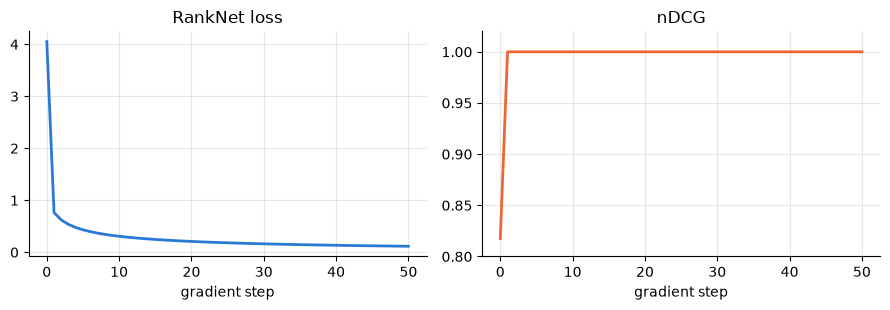

In [9]:
steps_, losses, ndcgs = zip(*[(t, loss, nd) for t, loss, nd, _ in history])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))
ax1.plot(steps_, losses, color="#2a78d6", lw=2)
ax1.set_title("RankNet loss")
ax2.plot(steps_, ndcgs, color="#eb6834", lw=2)
ax2.set_title("nDCG")
ax2.set_ylim(0.8, 1.02)
for ax in (ax1, ax2):
    ax.set_xlabel("gradient step")
    ax.grid(True, alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

After a single step, all six pairs are in the right order and nDCG reaches 1. The anchor weight
grows most: anchor text is the signal that separates the home page and Wikipedia from the course
page. The loss keeps falling after that, because pushing correct pairs further apart still pays,
even though the ranking no longer changes.

## 4. Listwise: LambdaRank

RankNet treats all pairs alike. Swapping ranks 1 and 2 costs the user far more than swapping
ranks 40 and 41, but both cost the same in $\mathcal{L}$. LambdaRank scales each pair's gradient by
the change in nDCG if the two documents swapped places in the current ranking:

$$\lambda_{ij} = \big|\Delta \text{nDCG}_{ij}\big| \cdot \sigma\big(-(s_i - s_j)\big)$$

In [10]:
def lambda_table(scores, grades):
    order = list(np.argsort(-scores))
    base = dcg(order, grades) / dcg(np.argsort(-grades), grades)
    rows = []
    for i, j in pairs:
        swapped = order.copy()
        a, b = swapped.index(i), swapped.index(j)
        swapped[a], swapped[b] = swapped[b], swapped[a]
        delta = abs(dcg(swapped, grades) / dcg(np.argsort(-grades), grades) - base)
        push = sigmoid(-(scores[i] - scores[j]))
        rows.append((delta * push, f"d{i + 1} > d{j + 1}", f"{a + 1}, {b + 1}", delta, push))
    return sorted(rows, reverse=True)

display_md(f"Current ranking by BM25F: **{order_of(bm25f)}**")
print_table(
    [[pair, ranks, f"{delta:.3f}", f"{push:.3f}", f"{lam:.3f}"]
     for lam, pair, ranks, delta, push in lambda_table(bm25f, y)],
    headers=["pair", "current ranks", "\\|ΔnDCG\\|", "σ(-(s_i - s_j))", "λ_ij"],
)

Current ranking by BM25F: **d2, d1, d4, d3**

| pair    | current ranks   |   \|ΔnDCG\| |   σ(-(s_i - s_j)) |   λ_ij |
|:--------|:----------------|------------:|------------------:|-------:|
| d1 > d2 | 2, 1            |       0.155 |             0.55  |  0.085 |
| d4 > d2 | 3, 1            |       0.105 |             0.574 |  0.06  |
| d1 > d3 | 2, 4            |       0.126 |             0.45  |  0.057 |
| d2 > d3 | 1, 4            |       0.12  |             0.401 |  0.048 |
| d4 > d3 | 3, 4            |       0.029 |             0.475 |  0.014 |
| d1 > d4 | 2, 3            |       0.027 |             0.475 |  0.013 |

The strongest push goes to $d_1 \succ d_2$, the mis-ordered pair at the top of the list. RankNet
would weight the pairs by the $\sigma$ column alone; LambdaRank multiplies by $|\Delta\text{nDCG}|$
and focuses on the top. **LambdaMART** trains gradient-boosted trees on these lambdas: each new
tree is fitted to the lambdas of the current model. We train it on real data in section 6.

## 5. Learning from Clicks

Human grades are expensive; clicks are free but biased. Users mostly click what is on top. We
simulate 20,000 users who see the four pages in BM25F order. A user looks at rank $k$ with
probability $p_k = 1/k$ (the **propensity**) and clicks a page they look at with probability
grade / 3.

In [11]:
rng = np.random.default_rng(0)
shown = np.argsort(-bm25f)                              # d2, d1, d4, d3 at ranks 1..4
propensity = 1 / np.arange(1, 5)
n_users = 20_000

examined = rng.random((n_users, 4)) < propensity       # does the user look at rank k?
attracted = rng.random((n_users, 4)) < y[shown] / 3     # would the user click that page?
clicks_at_rank = (examined & attracted).sum(axis=0)

clicks = np.zeros(4)
clicks[shown] = clicks_at_rank
ipw = np.zeros(4)
ipw[shown] = clicks_at_rank / propensity                # inverse propensity weighting

print_table(
    [[f"d{d + 1}", r + 1, int(clicks[d]), f"{clicks[d] / n_users:.3f}", f"{ipw[d] / n_users:.3f}",
      f"{y[d] / 3:.3f}"] for r, d in enumerate(shown)],
    headers=["page", "shown at rank", "clicks", "click rate", "IPW estimate", "true grade / 3"],
)
display_md(f"Ranking by clicks: **{order_of(clicks)}**  \n"
           f"Ranking by IPW-weighted clicks: **{order_of(ipw)}** (ideal: {order_of(y.astype(float))})")

| page   |   shown at rank |   clicks |   click rate |   IPW estimate |   true grade / 3 |
|:-------|----------------:|---------:|-------------:|---------------:|-----------------:|
| d2     |               1 |     6660 |        0.333 |          0.333 |            0.333 |
| d1     |               2 |     9951 |        0.498 |          0.995 |            1     |
| d4     |               3 |     4438 |        0.222 |          0.666 |            0.667 |
| d3     |               4 |        0 |        0     |          0     |            0     |

Ranking by clicks: **d1, d2, d4, d3**  
Ranking by IPW-weighted clicks: **d1, d4, d2, d3** (ideal: d1, d4, d2, d3)

The raw clicks favour the course page d2, because it was shown at rank 1, and rank it above the
Wikipedia article d4. Weighting each click at rank $k$ by $1/p_k$ removes the position bias: the
estimates match the true attractiveness, and the ranking is ideal. In practice, $p_k$ is unknown
and must be estimated, for example with small randomized swaps in a fraction of the result pages.

## 6. LambdaMART on Real Judgments: TREC-COVID

The toy example has four pages. Real rankers learn from thousands of judged pairs. TREC-COVID
(used in Chapter 6) has 50 topics and 66,336 human judgments on three grades: 0 (not relevant),
1 (partially), and 2 (relevant). Each topic has a short keyword query, the kind of query a web
user types. We take the judged papers of each topic as its candidate list, the output of the
retriever stage in the book's ranking stack.

### Features

For every topic-paper pair, the module [ch08_ltr.py](ch08_ltr.py) computes the chapter's content
signals on the two fields of a paper, title and abstract: BM25 per field, BM25F (title weight 3,
per-field length normalization), the proximity score of ch08-01, the fraction of query terms
present, and two query-independent features, the field lengths. A last feature is a neural score:
the cosine similarity of sentence embeddings (all-MiniLM-L6-v2, Chapter 5) between the topic's
question and the paper, precomputed because embedding 35,000 papers takes about half an hour on a CPU.
Scholarly papers have no links, so there is no PageRank or anchor text.

In [12]:
collection = load_collection("trec-covid")
assessments = load_assessments("trec-covid")

start = time.time()
F, grades, topic_of, doc_of = build_features(collection, assessments)
topics = assessments.query_ids()

display_md(f"**{F.shape[0]:,} judged pairs x {F.shape[1]} features**, {len(topics)} topics, "
           f"computed in {time.time() - start:.0f} s")
print_table(
    [[f] + [F[grades == g, k].mean() for g in (0, 1, 2)] for k, f in enumerate(FEATURES)],
    headers=["feature", "mean, grade 0", "mean, grade 1", "mean, grade 2"], floatfmt=".2f",
)

**66,336 judged pairs x 8 features**, 50 topics, computed in 43 s

| feature          |   mean, grade 0 |   mean, grade 1 |   mean, grade 2 |
|:-----------------|----------------:|----------------:|----------------:|
| bm25_title       |            1.01 |            1.55 |            2.42 |
| bm25_abstract    |            2.75 |            4.15 |            5.30 |
| bm25f            |            3.38 |            5.16 |            6.86 |
| log_proximity    |            0.78 |            1.36 |            1.89 |
| coverage         |            0.38 |            0.54 |            0.61 |
| dense            |            0.38 |            0.49 |            0.55 |
| log_title_len    |            2.61 |            2.66 |            2.71 |
| log_abstract_len |            4.46 |            4.61 |            4.65 |

Every content feature grows with the grade, but the distributions overlap: no single feature
separates the grades.

### One signal at a time

As a reference, we rank each topic's candidates by a single feature and average nDCG@10 over
all 50 topics:

In [13]:
def mean_ndcg(scores, topic_ids):
    """Mean nDCG@10 over topics, ranking each topic's candidates by score."""
    values = []
    for q in topic_ids:
        rows = np.where(topic_of == q)[0]
        ranked = doc_of[rows[np.argsort(-scores[rows], kind="stable")]]
        values.append(ndcg_at_k(list(ranked), assessments.qrels[q], k=10))
    return np.mean(values)

single = sorted(((mean_ndcg(F[:, k], topics), f) for k, f in enumerate(FEATURES)), reverse=True)
print_table([[f, v] for v, f in single], headers=["rank by", "nDCG@10"], floatfmt=".3f")

| rank by          |   nDCG@10 |
|:-----------------|----------:|
| dense            |     0.704 |
| bm25f            |     0.660 |
| bm25_title       |     0.628 |
| bm25_abstract    |     0.599 |
| coverage         |     0.544 |
| log_proximity    |     0.494 |
| log_title_len    |     0.317 |
| log_abstract_len |     0.264 |

### Pointwise, pairwise, listwise: five-fold cross-validation

We split the 50 topics into 5 folds of 10. Each model trains on 40 topics and ranks the 10
held-out topics, so every topic is ranked by a model that never saw it. We compare four models:

- **Linear, pointwise**: least squares on the grades.
- **Linear, pairwise**: RankNet by gradient descent, the same `ranknet_fit` as in section 3, on
  up to 3,000 sampled pairs per topic.
- **Trees, pointwise**: gradient-boosted regression trees (LightGBM) on the grades.
- **Trees, listwise**: LambdaMART (LightGBM with the `lambdarank` objective).

The linear models see standardized features. Each model runs twice: on the raw features, and on
features **normalized per topic**, scaled to the range 0 to 1 within each topic's candidate list.
The LETOR benchmarks ship their features in this form. The reason: a topic with rare query terms
produces high BM25 scores because of their IDF, and a topic with frequent terms produces low ones.
A BM25 score of 8 can therefore be mediocre for the first and excellent for the second, just as
the book notes that grades are not comparable across queries. A tree splits on absolute
thresholds, so it needs features that mean the same in every topic.

In [14]:
def normalize_per_topic(F):
    """Min-max scale every feature within the candidate list of each topic."""
    G = np.zeros_like(F)
    for q in topics:
        rows = topic_of == q
        lo, hi = F[rows].min(axis=0), F[rows].max(axis=0)
        G[rows] = (F[rows] - lo) / np.where(hi > lo, hi - lo, 1)
    return G

FQ = normalize_per_topic(F)
folds = np.array_split(np.random.default_rng(42).permutation(topics), 5)
TREE_PARAMS = dict(n_estimators=100, learning_rate=0.05, num_leaves=7, min_child_samples=200,
                   random_state=0, verbose=-1)

def standardize(train, test):
    mu, sd = train.mean(axis=0), train.std(axis=0) + 1e-9
    add_bias = lambda Z: np.hstack([(Z - mu) / sd, np.ones((len(Z), 1))])
    return add_bias(train), add_bias(test)

def sample_pair_differences(Z, g, t, per_topic=3000, seed=0):
    """Feature differences x_i - x_j of random pairs with g_i > g_j, per topic."""
    rng = np.random.default_rng(seed)
    diffs = []
    for q in np.unique(t):
        rows = np.where(t == q)[0]
        i, j = rng.choice(rows, (2, per_topic * 4))
        keep = g[i] > g[j]
        diffs.append(Z[i[keep][:per_topic]] - Z[j[keep][:per_topic]])
    return np.vstack(diffs)

def fit_predict(model, features, train, test):
    Ftr, Fte = features[train], features[test]
    g, t = grades[train], topic_of[train]
    if model == "linear, pointwise":
        Ztr, Zte = standardize(Ftr, Fte)
        return Zte @ np.linalg.lstsq(Ztr, g, rcond=None)[0]
    if model == "linear, pairwise (RankNet)":
        Ztr, Zte = standardize(Ftr, Fte)
        D = sample_pair_differences(Ztr, g, t)
        w, _ = ranknet_fit(D, np.zeros(Ztr.shape[1]), lr=0.5 / len(D), steps=300)
        return Zte @ w
    if model == "trees, pointwise":
        return lgb.LGBMRegressor(**TREE_PARAMS).fit(Ftr, g).predict(Fte)
    if model == "trees, listwise (LambdaMART)":
        group = [int((t == q).sum()) for q in dict.fromkeys(t)]   # rows are grouped by topic
        ranker = lgb.LGBMRanker(objective="lambdarank", label_gain=[0, 1, 2], **TREE_PARAMS)
        return ranker.fit(Ftr, g, group=group).predict(Fte)

def cross_validate(model, features):
    """Out-of-fold scores for every row: each fold is ranked by a model trained on the others."""
    scores = np.zeros(len(grades))
    for fold in folds:
        test = np.isin(topic_of, fold)
        scores[test] = fit_predict(model, features, ~test, test)
    return scores

MODELS = ["linear, pointwise", "linear, pairwise (RankNet)", "trees, pointwise",
          "trees, listwise (LambdaMART)"]
oof = {(m, rep): cross_validate(m, X_) for m in MODELS for rep, X_ in [("raw", F), ("norm", FQ)]}
baseline = F[:, FEATURES.index("bm25f")]

print_table(
    [["BM25F alone (no learning)", mean_ndcg(baseline, topics), mean_ndcg(baseline, topics)]]
    + [[m, mean_ndcg(oof[m, "raw"], topics), mean_ndcg(oof[m, "norm"], topics)] for m in MODELS],
    headers=["model", "nDCG@10, raw features", "nDCG@10, normalized per topic"], floatfmt=".3f",
)

| model                        |   nDCG@10, raw features |   nDCG@10, normalized per topic |
|:-----------------------------|------------------------:|--------------------------------:|
| BM25F alone (no learning)    |                   0.660 |                           0.660 |
| linear, pointwise            |                   0.789 |                           0.765 |
| linear, pairwise (RankNet)   |                   0.798 |                           0.791 |
| trees, pointwise             |                   0.778 |                           0.807 |
| trees, listwise (LambdaMART) |                   0.789 |                           0.816 |

Every learned ranker beats BM25F alone (0.66) by a wide margin, because it combines all
signals. The table also shows that model and features must fit together. The trees gain from
per-topic normalization (LambdaMART from about 0.79 to about 0.82), because their thresholds now
mean the same in every topic. The linear models do not gain; they lose a little. With normalized
features, the trees beat the linear models, and the listwise LambdaMART is best. Within one model
family, the listwise or pairwise loss beats the pointwise one, as the book argues. On 50 topics,
differences of about 0.01 are within the noise, so read the table for its pattern, not for the
third digit.

### What LambdaMART uses

The gain of a feature is the total loss reduction of all tree splits on that feature. We train
LambdaMART once on all 50 topics, with the normalized features, to look inside:

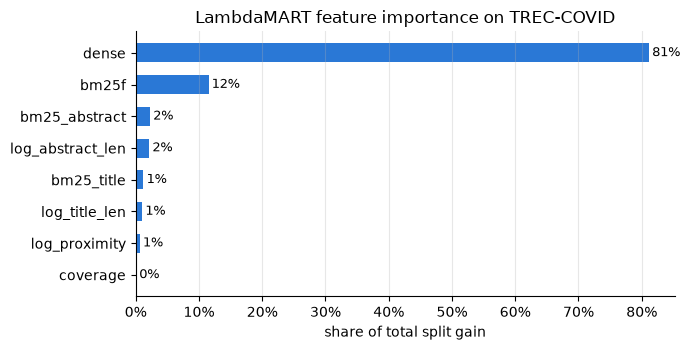

In [15]:
group = [int((topic_of == q).sum()) for q in topics]
full = lgb.LGBMRanker(objective="lambdarank", label_gain=[0, 1, 2], importance_type="gain",
                      **TREE_PARAMS).fit(FQ, grades, group=group)
gain = full.feature_importances_ / full.feature_importances_.sum()
order = np.argsort(gain)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh([FEATURES[k] for k in order], gain[order], color="#2a78d6", height=0.6)
for pos, k in enumerate(order):
    ax.text(gain[k] + 0.005, pos, f"{gain[k]:.0%}", va="center", fontsize=9)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("share of total split gain")
ax.set_title("LambdaMART feature importance on TREC-COVID")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

The dense score carries most of the gain, followed by BM25F. The other content features add little
on top: they are close relatives of BM25F, built from the same term statistics, so once the trees
have split on BM25F they bring little new information. Gain measures how much the model *uses* a
feature, not how useful the feature would be on its own: BM25 on the title alone reaches nDCG
0.63, but next to BM25F it is almost redundant.

### The neural score as one more feature

The book says that neural rankers have not replaced learning to rank, but joined it: their
output becomes one more feature. We train LambdaMART with and without the dense score, and
compare with each single signal:

In [16]:
content = [k for k, f in enumerate(FEATURES) if f != "dense"]
variants = {
    "BM25F alone": baseline,
    "dense score alone": F[:, FEATURES.index("dense")],
    "LambdaMART, content signals only": cross_validate("trees, listwise (LambdaMART)", FQ[:, content]),
    "LambdaMART, content signals + dense": oof["trees, listwise (LambdaMART)", "norm"],
}
print_table([[name, mean_ndcg(s, topics)] for name, s in variants.items()],
            headers=["ranker", "nDCG@10"], floatfmt=".3f")

| ranker                              |   nDCG@10 |
|:------------------------------------|----------:|
| BM25F alone                         |     0.660 |
| dense score alone                   |     0.704 |
| LambdaMART, content signals only    |     0.649 |
| LambdaMART, content signals + dense |     0.816 |

Without the dense score, LambdaMART is no better than BM25F alone: the remaining features are
variants of the same term statistics. The dense score alone beats BM25F, but the combination
beats both by far. The embedding model captures meaning that term statistics miss, and the term
statistics catch exact matches of rare terms that a small embedding model blurs. The learned
ranker combines both strengths.

## Payoff

In section 1, BM25F ranked the course page above the university home page (nDCG 0.817), and a
single gradient step on the pairwise loss fixed the order. On TREC-COVID, the same idea at scale
raises nDCG@10 from 0.66 for BM25F alone to about 0.82 for LambdaMART over eight signals. The
neural score helps most as one feature among others, not as a replacement for them.

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Learn the combination, optimize the order</strong><br>
Learning to rank turns the combination of signals into supervised learning. Pointwise, pairwise, and listwise differ in the training example and the loss, not in the model. Losses that target the order (pairwise) and the top of the list (listwise) match what users see. Trees learn interactions between signals, provided the features mean the same in every query.
</div>

## Summary

Pointwise learning predicts grades and spends effort on errors that do not change the ranking.
RankNet learns from pairs and fixes mis-ordered pairs by gradient descent. LambdaRank weights each
pair by its effect on nDCG, and LambdaMART trains boosted trees on these weights. Clicks provide
training data at scale once their position bias is removed by inverse propensity weighting. On
real judgments, a learned combination of the chapter's signals beats every single signal.

## Try it yourself

1. **Steeper position bias.** Set `propensity = 1 / np.arange(1, 5) ** 2` in section 5. Do raw
   clicks still find d1? Does IPW still recover the ideal ranking, and how noisy are the estimates?
2. **Feature ablation.** Call `cross_validate("trees, listwise (LambdaMART)", cols)` with
   different feature subsets, for example without `log_proximity`. Which feature costs most nDCG?
3. **Overfitting.** Increase `num_leaves` to 127 and `min_child_samples` to 5 in `TREE_PARAMS`.
   Does nDCG@10 on the held-out topics improve or drop?